In [10]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

# **1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса**

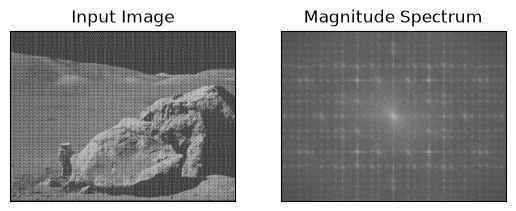

In [11]:
image = cv.imread("periodic_noise.jpg", cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(image), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]))

plt.subplot(121), plt.imshow(image, cmap="gray")
plt.title("Input Image"), plt.xticks([]), plt.yticks([])

plt.subplot(122), plt.imshow(magnitude_spectrum, cmap="gray")
plt.title("Magnitude Spectrum"), plt.xticks([]), plt.yticks([])
plt.show()

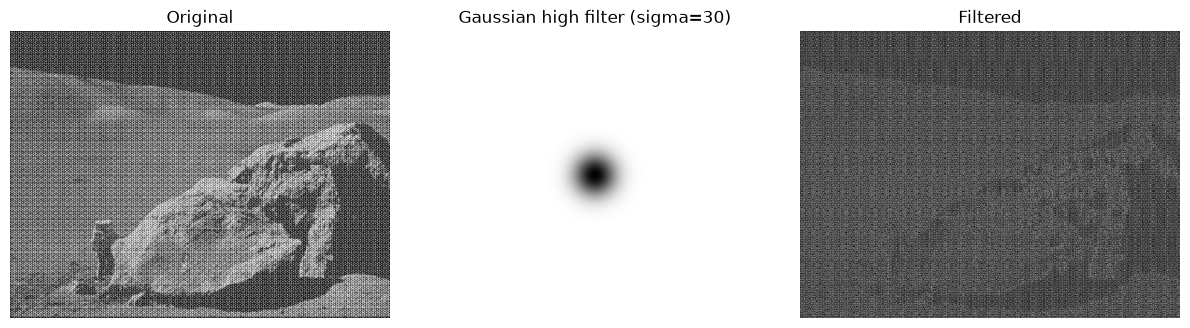

In [12]:
def gaussian_filter(shape, sigma, is_high = True):
    rows, cols = shape
    hrow, hcol = rows // 2, cols // 2
    x, y = np.meshgrid(np.arange(cols), np.arange(rows))

    gauss_mask = np.exp(-((x - hcol)**2 + (y - hrow)**2) / (2 * sigma**2))

    if is_high:
        return 1 - gauss_mask
    else:
        return gauss_mask
sigma = 30
mask_gaus = gaussian_filter(image.shape, sigma)

dft_shift = dft_shift * mask_gaus[:, :, np.newaxis]
image_idft = cv.idft(np.fft.ifftshift(dft_shift))
image_idft = cv.magnitude(image_idft[:, :, 0], image_idft[:, :, 1])
images = {
    "Original": image,
    f"Gaussian high filter (sigma={sigma})": mask_gaus,
    "Filtered": image_idft,
}

# Show images
fig, axs = plt.subplots(1, 3, figsize=(12, 5))

col = 0
for col, (key, img) in enumerate(images.items()):
    axs[col].imshow(img, cmap="gray")
    axs[col].set_title(key)
    axs[col].axis("off")

plt.tight_layout()
plt.show()

# **2. Реализуйте вычисление свертки с помощью преобразования Фурье**

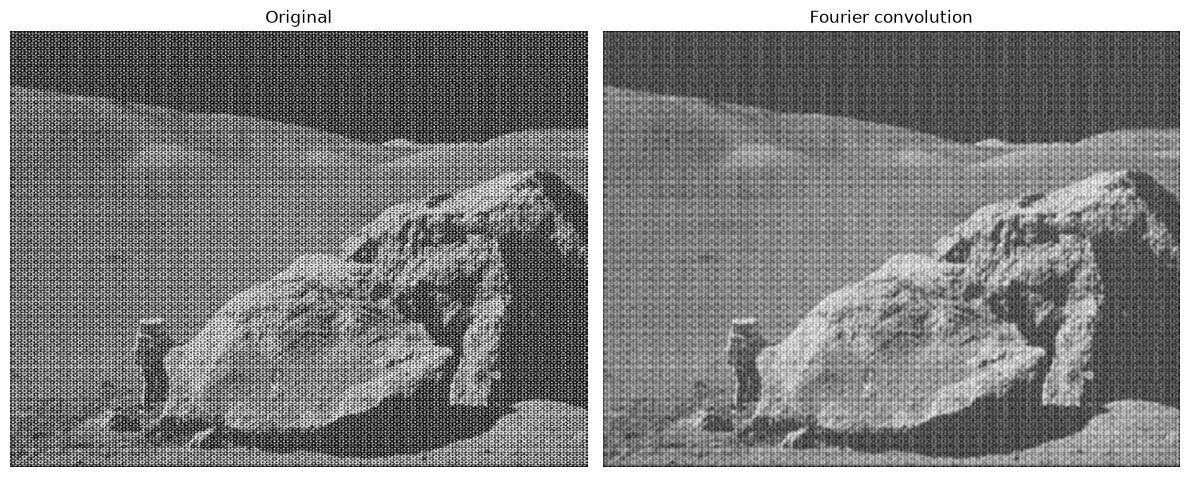

In [13]:
def fft_convolution(image, kernel):
    img_h, img_w = image.shape
    ker_h, ker_w = kernel.shape
    
    out_h = img_h + ker_h - 1
    out_w = img_w + ker_w - 1
    
    padded_img = np.zeros((out_h, out_w), dtype=np.float32)
    padded_ker = np.zeros((out_h, out_w), dtype=np.float32)
    
    padded_img[:img_h, :img_w] = image
    padded_ker[:ker_h, :ker_w] = kernel
    
    F = np.fft.fft2(padded_img)
    H = np.fft.fft2(padded_ker)
    
    G = F * H
    
    result_padded = np.real(np.fft.ifft2(G))
    
    pad_h = (ker_h - 1) // 2
    pad_w = (ker_w - 1) // 2
    
    result = result_padded[pad_h : pad_h + img_h, pad_w : pad_w + img_w]
    
    return result

gaussian_kernel = cv.getGaussianKernel(5, 1.0)
gaussian_2d = np.outer(gaussian_kernel, gaussian_kernel)

result_fft = fft_convolution(image.astype(np.float32), gaussian_2d)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].imshow(image, cmap='gray')
axs[0].set_title('Original')
axs[0].axis('off')

axs[1].imshow(result_fft, cmap='gray')
axs[1].set_title('Fourier convolution')
axs[1].axis('off')

plt.tight_layout()
plt.show()

# **3. Реализуйте удаление периодического шума с помощью преобразования Фурье**

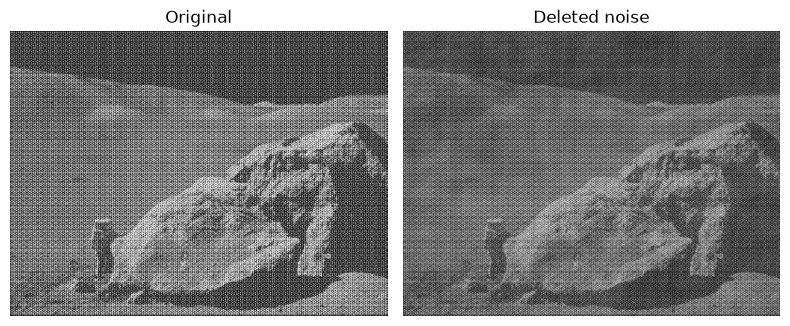

In [14]:
from skimage.feature import peak_local_max
def periodic_noise_deletion(img):
    dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
    dft_shift = np.fft.fftshift(dft)
    magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]))
    local_maxum = peak_local_max(magnitude_spectrum, min_distance=15, threshold_abs=200)

    mask = np.copy(dft_shift)
    mask[:, :, :] = 1

    rows, cols = img.shape
    hrow, hcol = rows // 2, cols // 2
    for i in local_maxum:
        r = np.int32(((i[0] - hrow)**2 + (i[1] - hcol)**2) ** (1 / 2))
        cv.circle(mask, (hrow, hcol), r, (0, 0))

    dft_shift = dft_shift * mask
    image_idft = cv.idft(np.fft.ifftshift(dft_shift))
    image_idft = cv.magnitude(image_idft[:, :, 0], image_idft[:, :, 1])

    return image_idft
images = {
    "Original": image,
    "Deleted noise": periodic_noise_deletion(image),
}

# Show images
fig, axs = plt.subplots(1, 2, figsize=(8, 5))

col = 0
for col, (key, img) in enumerate(images.items()):
    axs[col].imshow(img, cmap="gray")
    axs[col].set_title(key)
    axs[col].axis("off")

plt.tight_layout()
plt.show()